# Tecnológico de Monterrey
## Proyecto Integrador — Equipo 23
## Avance 2. Ingeniería de características
**Integrantes**
- Edmundo Carmona Galindo - A01796647
- Jaqueline Villafranca Hernández - A01656679
- Edgar Omar Cruz Mendoza - A01795590

## Parte 1 Datos pre-mortem

Datos de fichas de desaperecidos, recuperado de la página **"Alerta Nacional de Búsqueda de Personas"

Recuperado de `https://comisionacionaldebusqueda.segob.gob.mx/alerta-nacional/` del 8 al 9 de octubre del 2026


In [0]:
import unicodedata
import numpy as np
import pandas as pd
from scipy import stats

CATALOG = "proyecto_mna"
SCHEMA = "fichas_busqueda"
T_PERSONA = f"{CATALOG}.{SCHEMA}.fichas_persona_silver"
T_TATUAJES = f"{CATALOG}.{SCHEMA}.fichas_tatuajes_silver"
T_SENAS = f"{CATALOG}.{SCHEMA}.fichas_senas_silver"
T_VESTIMENTA = f"{CATALOG}.{SCHEMA}.fichas_vestimenta_silver"

# --- Carga desde Spark a pandas (75 filas — cómodo en memoria) ---
df_persona = spark.table(T_PERSONA).toPandas()
df_tatuajes = spark.table(T_TATUAJES).toPandas()
df_senas = spark.table(T_SENAS).toPandas()
df_vestimenta = spark.table(T_VESTIMENTA).toPandas()

print(f"persona: {len(df_persona)} filas | tatuajes: {len(df_tatuajes)} | senas: {len(df_senas)} | vestimenta: {len(df_vestimenta)}")

# --- Normalización de SIN_DATO → NaN ---
# Justificación: SIN_DATO significa "no mencionado en la ficha"; para el modelo
# es un valor faltante genuino, no una categoría informativa. Tratarlo como NaN
# permite imputar correctamente y evita que el modelo aprenda un patrón artificial.
SIN_DATO_VALUES = {"SIN_DATO", "sin_dato", "SIN_DATO", None, ""}
cat_cols_persona = ["sexo", "complexion", "color_piel", "forma_cara", "cabello_color",
    "cabello_largo", "cabello_tipo", "ojos_color", "ojos_tamano", "nariz",
    "boca", "labios", "vello_facial", "calidad_foto", "estado_hechos", "municipio_hechos"]

for c in cat_cols_persona:
    df_persona[c] = df_persona[c].replace("SIN_DATO", np.nan)

# --- Normalización de estado_hechos ---
# El LLM dejó variantes tipográficas del mismo estado; se unifican para reducir cardinalidad.
NORMALIZACION_ESTADO = {
    "ESTADO_DE_MEXICO": "ESTADO_DE_MEXICO", "MEXICO": "ESTADO_DE_MEXICO",
    "MICH": "MICHOACAN", "TAMUALIPAS": "TAMAULIPAS",
    "CIUDAD_DE_MEXICO": "CDMX", "ESTADO": "SIN_DATO", "MUNICIPIO": "SIN_DATO",
    "MORENO": "SIN_DATO",
}
def _canon_estado(txt):
    if pd.isna(txt) or txt == "SIN_DATO":
        return np.nan
    t = unicodedata.normalize("NFKD", str(txt)).encode("ascii", "ignore").decode().upper().strip()
    t = "_".join(t.replace("-", " ").split())
    return NORMALIZACION_ESTADO.get(t, t)

df_persona["estado_hechos_norm"] = df_persona["estado_hechos"].apply(_canon_estado)

# Convertir fecha_hechos a datetime
df_persona["fecha_hechos_dt"] = pd.to_datetime(df_persona["fecha_hechos"], errors="coerce")

nulls = df_persona[cat_cols_persona + ["edad_desaparicion", "estatura_cm", "peso_kg"]].isna().sum()
print(f"Columnas con nulos: {(nulls[nulls > 0]).shape[0]}/{len(nulls)} | Top: {nulls[nulls > 0].idxmax()} ({nulls.max()})")
print(f"Estados únicos: {df_persona['estado_hechos_norm'].nunique()} | Top: {df_persona['estado_hechos_norm'].value_counts().head(3).to_dict()}")

persona: 60 filas | tatuajes: 100 | senas: 25 | vestimenta: 82
Columnas con nulos: 13/19 | Top: nariz (26)
Estados únicos: 13 | Top: {'QUERETARO': 43, 'ESTADO_DE_MEXICO': 3, 'BAJA_CALIFORNIA_SUR': 2}


## 1. Generación de nuevas características
Se derivan variables nuevas a partir de los campos crudos para capturar información compuesta o de mayor valor discriminativo.

In [0]:
# ============================================================================
# 1.1 IMC (Índice de Masa Corporal) = peso(kg) / estatura(m)^2
# Justificación: estatura y peso por separado tienen poca capacidad discriminativa
# cuando faltan datos (25% y 12% nulos respectivamente). El IMC combina ambos en
# una sola variable clínicamente interpretable que reduce dimensionalidad.
# ============================================================================
df_persona["estatura_m"] = df_persona["estatura_cm"] / 100
df_persona["imc"] = df_persona["peso_kg"] / (df_persona["estatura_m"] ** 2)
df_persona["imc"] = df_persona["imc"].round(1)
print("IMC — stats:")
print(df_persona["imc"].describe().to_string())

# ============================================================================
# 1.2 Indicadores binarios de presencia de tatuajes / señas / vestimenta
# Justificación: n_tatuajes=0 vs >0 es más discriminativo que el conteo exacto
# cuando la distribución es muy sesgada (89% tienen tatuajes).
# ============================================================================
df_persona["has_tatuajes"] = (df_persona["n_tatuajes"] > 0).astype(int)
df_persona["has_senas"] = (df_persona["n_senas"] > 0).astype(int)
df_persona["has_vestimenta"] = (df_persona["n_prendas"] > 0).astype(int)

# ============================================================================
# 1.3 Región geográfica agrupada
# Justificación: estado_hechos tiene ~15 valores únicos para 75 filas. Agrupar
# en regiones reduce la cardinalidad sin perder información geográfica relevante.
# ============================================================================
REGION_MAP = {
    "QUERETARO": "Bajio", "GUANAJUATO": "Bajio", "MICHOACAN": "Bajio",
    "ESTADO_DE_MEXICO": "Centro", "CDMX": "Centro", "HIDALGO": "Centro",
    "PUEBLA": "Centro", "MORELOS": "Centro", "Tlaxcala": "Centro",
    "SONORA": "Norte", "BAJA_CALIFORNIA_SUR": "Norte", "CHIHUAHUA": "Norte",
    "TAMAULIPAS": "Norte", "SINALOA": "Norte",
    "SAN_LUIS_POTOSI": "Centro_Norte", "ZACATECAS": "Centro_Norte",
    "VERACRUZ": "Golfo", "CHIAPAS": "Sureste",
}
df_persona["region_geografica"] = df_persona["estado_hechos_norm"].map(REGION_MAP)
print("\nRegión geográfica:")
print(df_persona["region_geografica"].value_counts().to_string())

# ============================================================================
# 1.4 Días transcurridos desde la fecha de los hechos
# Justificación: la antigüedad del caso puede influir en la disponibilidad de
# información y en la urgencia de la búsqueda. Se calcula respecto a la fecha actual.
# ============================================================================
fecha_ref = pd.Timestamp("2026-10-10")
df_persona["dias_desde_hechos"] = (fecha_ref - df_persona["fecha_hechos_dt"]).dt.days
print("\nDías desde hechos — stats:")
print(df_persona["dias_desde_hechos"].describe().to_string())

# ============================================================================
# 1.5 Densidad de tatuajes (tatuajes por año de edad)
# Justificación: una persona de 50 años con 3 tatuajes tiene distinto perfil que
# una de 18 años con 3 tatuajes. Normaliza por edad.
# ============================================================================
df_persona["densidad_tatuajes"] = df_persona["n_tatuajes"] / df_persona["edad_desaparicion"].clip(lower=1)
print("\nDensidad de tatuajes — stats:")
print(df_persona["densidad_tatuajes"].describe().to_string())

# ============================================================================
# 1.6 Agregaciones de tablas hijas (tatuajes, señas, vestimenta)
# Justificación: las tablas hijas tienen relación 1:N; para modelar a nivel persona
# se agregan en características resumen (conteo por categoría, diversidad).
# ============================================================================
# Diversidad de regiones corporales con tatuaje
tat_regiones = df_tatuajes.groupby("id_ficha")["region"].nunique().rename("n_regiones_tat")
df_persona = df_persona.merge(tat_regiones, on="id_ficha", how="left")
df_persona["n_regiones_tat"] = df_persona["n_regiones_tat"].fillna(0).astype(int)

# ¿Tiene tatuaje con texto legible?
tat_texto = df_tatuajes[df_tatuajes["texto_legible"].notna() & (df_tatuajes["texto_legible"] != "SIN_DATO")] \
    .groupby("id_ficha").size().rename("has_tatuaje_texto")
df_persona = df_persona.merge(tat_texto, on="id_ficha", how="left")
df_persona["has_tatuaje_texto"] = (df_persona["has_tatuaje_texto"].fillna(0) > 0).astype(int)

# Categoría de tatuaje más frecuente por persona (modo)
def moda_no_nan(series):
    s = series.dropna()
    s = s[s != "SIN_DATO"]
    return s.mode().iloc[0] if len(s) > 0 else np.nan

tat_cat_top = df_tatuajes.groupby("id_ficha")["categoria"].apply(moda_no_nan).rename("tat_categoria_top")
df_persona = df_persona.merge(tat_cat_top, on="id_ficha", how="left")

# Diversidad de tipos de vestimenta
vest_tipos = df_vestimenta.groupby("id_ficha")["tipo"].nunique().rename("n_tipos_vestimenta")
df_persona = df_persona.merge(vest_tipos, on="id_ficha", how="left")
df_persona["n_tipos_vestimenta"] = df_persona["n_tipos_vestimenta"].fillna(0).astype(int)

print("\nNuevas features generadas:")
new_cols = ["imc", "has_tatuajes", "has_senas", "has_vestimenta", "region_geografica",
            "dias_desde_hechos", "densidad_tatuajes", "n_regiones_tat",
            "has_tatuaje_texto", "tat_categoria_top", "n_tipos_vestimenta"]
print(df_persona[new_cols].describe(include="all").to_string())

IMC — stats:
count    52.000000
mean     24.178846
std       4.387922
min      13.000000
25%      21.575000
50%      23.800000
75%      26.000000
max      37.000000

Región geográfica:
region_geografica
Bajio           40
Centro          19
Norte            9
Centro_Norte     1
Sureste          1
Golfo            1

Días desde hechos — stats:
count      73.000000
mean     1716.342466
std      1569.383869
min         3.000000
25%       904.000000
50%      1322.000000
75%      2301.000000
max      7463.000000

Densidad de tatuajes — stats:
count    75.000000
mean      0.073159
std       0.120814
min       0.000000
25%       0.028175
50%       0.054054
75%       0.072751
max       1.000000

Nuevas features generadas:
              imc  has_tatuajes  has_senas  has_vestimenta region_geografica  dias_desde_hechos  densidad_tatuajes  n_regiones_tat  has_tatuaje_texto tat_categoria_top  n_tipos_vestimenta
count   52.000000     75.000000  75.000000       75.000000                71          73

## 2. Discretización (Binning)
Se convierten variables continuas en categorías ordinales para reducir el ruido, capturar relaciones no lineales y facilitar la interpretabilidad del modelo.

In [0]:
# ============================================================================
# 2.1 Grupos de edad (binning por rangos clínicamente significativos)
# Justificación: la edad va de 1 a 99 años con outliers (edad=99 probablemente
# error de extracción). Los rangos siguen las categorías legales/médicas usadas
# en búsqueda de personas desaparecidas en México.
# ============================================================================
AGE_BINS = [0, 12, 18, 30, 50, 120]
AGE_LABELS = ["infante_adolescente", "joven_adulto", "adulto_joven", "adulto", "adulto_mayor"]
df_persona["grupo_edad"] = pd.cut(df_persona["edad_desaparicion"], bins=AGE_BINS,
                                 labels=AGE_LABELS, right=False)
print("Grupo de edad:")
print(df_persona["grupo_edad"].value_counts().sort_index().to_string())

# ============================================================================
# 2.2 Categorías de IMC (clasificación OMS)
# Justificación: la OMS define cortes estándar internacionalmente válidos.
# ============================================================================
IMC_BINS = [0, 18.5, 25, 30, 100]
IMC_LABELS = ["bajo_peso", "normal", "sobrepeso", "obesidad"]
df_persona["categoria_imc"] = pd.cut(df_persona["imc"], bins=IMC_BINS,
                                     labels=IMC_LABELS, right=False)
print("\nCategoría IMC:")
print(df_persona["categoria_imc"].value_counts().sort_index().to_string())

# ============================================================================
# 2.3 Rangos de estatura (corto / medio / alto)
# Justificación: discretizar la estatura en terciles permite capturar el efecto
# de "persona alta vs baja" sin depender de un valor exacto que frecuentemente falta.
# ============================================================================
est_vals = df_persona["estatura_cm"].dropna()
df_persona["rango_estatura"] = pd.cut(df_persona["estatura_cm"],
    bins=[0, 155, 170, 200], labels=["bajo", "medio", "alto"], right=False)
print("\nRango estatura:")
print(df_persona["rango_estatura"].value_counts().sort_index().to_string())

# ============================================================================
# 2.4 Tiempo transcurrido en categorías
# Justificación: discretizar días desde los hechos en ventanas temporalmente
# significativas para búsqueda (caso reciente vs antiguo vs histórico).
# ============================================================================
DIAS_BINS = [0, 365, 1825, 10000]
DIAS_LABELS = ["recente_1ano", "intermedio_5anos", "historico"]
df_persona["antiguedad_caso"] = pd.cut(df_persona["dias_desde_hechos"],
    bins=DIAS_BINS, labels=DIAS_LABELS, right=False)
print("\nAntigüedad del caso:")
print(df_persona["antiguedad_caso"].value_counts().sort_index().to_string())

Grupo de edad:
grupo_edad
infante_adolescente     3
joven_adulto           15
adulto_joven           23
adulto                 24
adulto_mayor           10

Categoría IMC:
categoria_imc
bajo_peso     4
normal       30
sobrepeso    14
obesidad      4

Rango estatura:
rango_estatura
bajo      4
medio    27
alto     25

Antigüedad del caso:
antiguedad_caso
recente_1ano        16
intermedio_5anos    23
historico           34


## 3. Codificación
Las variables categóricas se convierten a numéricas. Se distingue entre:
- **Ordinal**: la categoría tiene un orden intrínseco (ej. labios DELGADOS < MEDIANOS < GRUESOS).
- **One-Hot / Nominal**: no hay orden; cada categoría es una dimensión binaria independiente.

La elección se justifica caso por caso según el significado de la variable.

In [0]:
from sklearn.preprocessing import OrdinalEncoder

# ============================================================================
# 3.1 Codificación Ordinal
# Justificación: estas variables tienen un orden natural (pequeño < mediano < grande,
# regular < buena). Asignar enteros preserva el orden para el modelo.
# ============================================================================
ORDINAL_MAPS = {
    "calidad_foto": ["REGULAR", "BUENA"],
    "labios": ["DELGADOS", "MEDIANOS", "GRUESOS"],
    "boca": ["PEQUENA", "MEDIANA", "GRANDE"],
    "ojos_tamano": ["CHICOS", "MEDIANOS", "GRANDES"],
    "cabello_largo": ["CORTO", "MEDIANO", "LARGO"],
    "complexion": ["DELGADA", "MEDIANA", "ROBUSTA"],
    "grupo_edad": list(AGE_LABELS),
    "categoria_imc": list(IMC_LABELS),
    "rango_estatura": ["bajo", "medio", "alto"],
    "antiguedad_caso": list(DIAS_LABELS),
}

df_encoded = df_persona.copy()
ordinal_encoded_cols = []
for col, categories in ORDINAL_MAPS.items():
    enc = OrdinalEncoder(categories=[categories], handle_unknown="use_encoded_value", unknown_value=-1)
    vals = df_encoded[[col]].astype(str).values
    df_encoded[f"{col}_ord"] = enc.fit_transform(vals).astype(int)
    # Marcar -1 (desconocido) como NaN
    df_encoded.loc[df_encoded[f"{col}_ord"] == -1, f"{col}_ord"] = np.nan
    ordinal_encoded_cols.append(f"{col}_ord")

print("Codificación ordinal completada:")
print(df_encoded[ordinal_encoded_cols].describe().to_string())

# ============================================================================
# 3.2 Codificación One-Hot (Nominal)
# Justificación: estas variables no tienen un orden natural; una codificación
# ordinal introduciría una relación espuría. One-Hot crea una columna binaria
# por categoría, evitando suponer proximidad entre categorías.
# ============================================================================
ONEHOT_COLS = [
    "sexo",                  # HOMBRE / MUJER — binaria nominal
    "color_piel",            # MORENO / MORENO_CLARO / BLANCO — nominal
    "forma_cara",            # OVALADA / REDONDA / CUADRADA — nominal
    "cabello_color",         # NEGRO / CASTANO_OSCURO / etc. — nominal
    "cabello_tipo",          # LACIO / ONDULADO / RIZADO / CRESPO — nominal
    "ojos_color",            # CAFES_OSCUROS / NEGROS / etc. — nominal
    "region_geografica",     # Bajio / Centro / Norte — nominal
    "tat_categoria_top",     # categoría de tatuaje más frecuente
]

# Eliminar filas con NaN en las columnas one-hot para el encoding
df_onehot = pd.get_dummies(df_encoded, columns=ONEHOT_COLS, prefix=ONEHOT_COLS, dummy_na=False, dtype=int)

# Listar las nuevas columnas one-hot creadas
onehot_new_cols = [c for c in df_onehot.columns if any(c.startswith(col + "_") for col in ONEHOT_COLS)]
print(f"\nCodificación One-Hot: {len(onehot_new_cols)} columnas creadas")
print(onehot_new_cols)

# ============================================================================
# 3.3 Variables ya numéricas / binarias (no requieren codificación)
# ============================================================================
BINARY_COLS = ["has_tatuajes", "has_senas", "has_vestimenta", "has_tatuaje_texto",
               "menciona_perfil_genetico", "menciona_huellas"]
NUMERIC_COLS = ["edad_desaparicion", "estatura_cm", "peso_kg", "imc",
                "n_tatuajes", "n_senas", "n_prendas", "dias_desde_hechos",
                "densidad_tatuajes", "n_regiones_tat", "n_tipos_vestimenta"]

print(f"\nVariables binarias: {BINARY_COLS}")
print(f"Variables numéricas continuas: {NUMERIC_COLS}")

Codificación ordinal completada:
       calidad_foto_ord  labios_ord   boca_ord  ojos_tamano_ord  cabello_largo_ord  complexion_ord  grupo_edad_ord  categoria_imc_ord  rango_estatura_ord  antiguedad_caso_ord
count         75.000000   67.000000  69.000000        70.000000          65.000000       73.000000       75.000000          52.000000           56.000000            73.000000
mean           0.266667    0.820896   0.898551         1.057143           0.738462        0.657534        2.306667           1.346154            1.375000             1.246575
std            0.445195    0.796305   0.572531         0.535297           0.538427        0.803105        1.065089           0.737899            0.619751             0.795488
min            0.000000    0.000000   0.000000         0.000000           0.000000        0.000000        0.000000           0.000000            0.000000             0.000000
25%            0.000000    0.000000   1.000000         1.000000           0.000000        0.

## 4. Escalamiento y Transformaciones
Se aplican técnicas de escalamiento para que las variables numéricas estén en rangos comparables, y transformaciones para corregir asimetría en la distribución.

- **Min-Max**: lleva todas las variables al rango [0, 1]. Útil cuando se necesitan valores acotados (ej. redes neuronales, distancia coseno).
- **Estandarización (Z-score)**: media 0, desviación 1. Más robusta a outliers que Min-Max.
- **Logarítmica**: para variables de conteo con sesgo positivo (asimetría derecha).
- **Yeo-Johnson**: generalización de Box-Cox que soporta valores negativos y cero.

In [0]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.preprocessing import PowerTransformer

# ============================================================================
# Preparar dataset numérico para escalamiento
# Seleccionar solo las columnas numéricas que serán usadas en el modelo
# (ordinale-encoded, one-hot, binarias, y continuas originales)
# ============================================================================
FEATURES_FOR_SCALING = NUMERIC_COLS + ordinal_encoded_cols + BINARY_COLS

# Construir la matriz de features final
df_features = df_onehot.copy()
# Asegurar que las columnas ordinales estén disponibles
df_features[ordinal_encoded_cols] = df_encoded[ordinal_encoded_cols].values

# Imputar NaN con la mediana antes de escalar (justificación: la mediana es
# robusta a outliers y a la distribución sesgada de estas variables)
df_model = df_features[FEATURES_FOR_SCALING + onehot_new_cols].copy()
for c in FEATURES_FOR_SCALING:
    if df_model[c].isna().any():
        med = df_model[c].median()
        df_model[c] = df_model[c].fillna(med)

print(f"Matriz de features: {df_model.shape[0]} filas x {df_model.shape[1]} columnas")
print(f"NaNs restantes: {df_model.isna().sum().sum()}")

# ============================================================================
# 4.1 Escalamiento Min-Max [0, 1]
# Justificación: necesario para algoritmos basados en distancia (KNN, SVM con
# kernel RBF) y para redes neuronales. Las variables ordinales y binarias no
# necesitan escalamiento, pero las continuas sí.
# ============================================================================
CONTINUOUS_COLS = ["edad_desaparicion", "estatura_cm", "peso_kg", "imc",
                   "dias_desde_hechos", "densidad_tatuajes", "n_tatuajes",
                   "n_senas", "n_prendas", "n_regiones_tat", "n_tipos_vestimenta"]

scaler_mm = MinMaxScaler()
df_scaled_mm = df_model.copy()
df_scaled_mm[CONTINUOUS_COLS] = scaler_mm.fit_transform(df_model[CONTINUOUS_COLS])
print(f"Min-Max: {len(CONTINUOUS_COLS)} vars → [0,1]")

# ============================================================================
# 4.2 Estandarización (Z-score)
# Justificación: preferida para PCA y regresión lineal porque la media 0 y
# desviación 1 aseguran que ninguna variable dominate por su escala.
# ============================================================================
scaler_std = StandardScaler()
df_scaled_std = df_model.copy()
df_scaled_std[CONTINUOUS_COLS] = scaler_std.fit_transform(df_model[CONTINUOUS_COLS])
print(f"Z-score: {len(CONTINUOUS_COLS)} vars → media=0, std=1")

# ============================================================================
# 4.3 Transformación logarítmica para n_tatuajes
# Justificación: n_tatuajes tiene sesgo positivo (89% tienen tatuajes pero el
# conteo varía de 0 a 8). log(1+x) comprime la cola derecha y reduce el sesgo.
# ============================================================================
skew_before = df_model["n_tatuajes"].skew()
df_model["n_tatuajes_log"] = np.log1p(df_model["n_tatuajes"])
skew_after = df_model["n_tatuajes_log"].skew()
print(f"\nLog transform n_tatuajes: skew {skew_before:.3f} -> {skew_after:.3f}")

# ============================================================================
# 4.4 Transformación Yeo-Johnson para edad_desaparicion
# Justificación: la edad tiene asimetría moderada (skew=0.59) y un outlier en
# edad=99. Yeo-Johnson (a diferencia de Box-Cox) soporta valores negativos y
# cero, y se elige sobre log porque la edad puede tener valores cercanos a 0.
# ============================================================================
pt = PowerTransformer(method="yeo-johnson")
edad_raw = df_model["edad_desaparicion"].values.reshape(-1, 1)
edad_yj = pt.fit_transform(edad_raw)
df_model["edad_yj"] = edad_yj.flatten()
skew_edad_before = df_model["edad_desaparicion"].skew()
skew_edad_after = pd.Series(edad_yj.flatten()).skew()
print(f"Yeo-Johnson edad: skew {skew_edad_before:.3f} -> {skew_edad_after:.3f}")

# ============================================================================
# 4.5 Transformación Yeo-Johnson para IMC
# Justificación: el IMC también presenta asimetría por valores extremos.
# ============================================================================
imc_raw = df_model["imc"].values.reshape(-1, 1)
imc_yj = pt.fit_transform(imc_raw)
df_model["imc_yj"] = imc_yj.flatten()
print(f"Yeo-Johnson IMC: skew {df_model['imc'].skew():.3f} -> {pd.Series(imc_yj.flatten()).skew():.3f}")

print("\nTransformaciones completadas. Columnas adicionales:")
print(["n_tatuajes_log", "edad_yj", "imc_yj"])

Matriz de features: 75 filas x 59 columnas
NaNs restantes: 0

Min-Max scaling — estadísticas:
     edad_desaparicion  estatura_cm  peso_kg  imc  dias_desde_hechos  densidad_tatuajes  n_tatuajes  n_senas  n_prendas  n_regiones_tat  n_tipos_vestimenta
min                0.0          0.0      0.0  0.0                0.0                0.0         0.0      0.0        0.0             0.0                 0.0
max                1.0          1.0      1.0  1.0                1.0                1.0         1.0      1.0        1.0             1.0                 1.0

Estandarización — estadísticas:
      edad_desaparicion  estatura_cm  peso_kg    imc  dias_desde_hechos  densidad_tatuajes  n_tatuajes  n_senas  n_prendas  n_regiones_tat  n_tipos_vestimenta
mean              0.000        0.000   -0.000  0.000              0.000              0.000       0.000    0.000      0.000          -0.000              -0.000
std               1.007        1.007    1.007  1.007              1.007              1.

## 5. Selección de Características
Se aplican **métodos de filtrado** (independientes del modelo) para reducir dimensionalidad:

- **Umbral de varianza**: elimina variables constantes o casi constantes que no aportan información.
- **Correlación**: elimina variables redundantes (alta correlación entre sí).
- **Chi-cuadrada ($\chi^2$)**: mide independencia entre variables categóricas y una variable de **blocking** (sexo). En record linkage, el *blocking* descarta pares imposibles antes del cotejo; identificar qué features discriminan entre bloques ayuda a seleccionar criterios de blocking efectivos.
- **ANOVA F-test**: mide diferencia de medias de variables continuas entre los mismos bloques (sexo). Complementa $\chi^2$ identificando variables continuas con poder discriminativo para blocking.

Y **técnicas de extracción** que proyectan las características originales a un espacio de menor dimensión:

- **PCA (Análisis de Componentes Principales)**: proyección lineal que maximiza varianza.
- **FA (Análisis Factorial)**: modela varianza compartida entre variables mediante factores latentes.

In [0]:
from sklearn.feature_selection import VarianceThreshold, SelectKBest, chi2, f_classif

# ============================================================================
# Preparar la matriz final de features (todas numéricas, imputadas)
# ============================================================================
# Usar todas las columnas generadas: continuas + ordinales + binarias + one-hot
ALL_FEATURES = CONTINUOUS_COLS + ordinal_encoded_cols + BINARY_COLS + onehot_new_cols + ["n_tatuajes_log", "edad_yj", "imc_yj"]
ALL_FEATURES = list(dict.fromkeys(ALL_FEATURES))  # deduplicar preservando orden

X = df_model[ALL_FEATURES].copy()
# Imputar cualquier NaN restante con 0
X = X.fillna(0)

# Variable de blocking para Chi2 y ANOVA: sexo (HOMBRE / MUJER)
# Justificación: en record linkage, el blocking descarta pares imposibles antes
# del cotejo por similitud. sexo es el criterio de blocking más natural en este
# dominio. Chi2 y ANOVA identifican qué features discriminan entre bloques,
# ayudando a seleccionar criterios de blocking efectivos. No es un target de
# clasificación — el modelo final es retrieval por Vector Search k-NN.
y = df_persona["sexo"].values

print(f"Matriz X: {X.shape[0]} filas x {X.shape[1]} columnas")
print(f"Variable de blocking (sexo): {pd.Series(y).value_counts().to_dict()}")

# ============================================================================
# 5.1 Umbral de Varianza
# Justificación: una variable con varianza ≈0 no discrimina entre observaciones.
# Se elimina cualquier columna con varianza < 0.01 (prácticamente constante).
# ============================================================================
selector_var = VarianceThreshold(threshold=0.01)
selector_var.fit(X)
low_var_cols = X.columns[~selector_var.get_support()].tolist()
print(f"\n--- Umbral de Varianza (threshold=0.01) ---")
print(f"Eliminadas: {low_var_cols}")
X_var = X.drop(columns=low_var_cols)
print(f"Features restantes: {X_var.shape[1]}")

# ============================================================================
# 5.2 Correlación de Pearson
# Justificación: variables con |r| > 0.85 son redundantes; mantener ambas
# no añade información pero sí ruido y colinearidad (perjudicial para la
# vectorización y retrieval por similitud en Vector Search).
# Se elimina la de mayor correlación promedio con las demás.
# ============================================================================
corr_matrix = X_var.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
# Correlación promedio de cada variable con las demás
mean_abs_corr = corr_matrix.mean(axis=1)
to_drop_corr = set()
for col in upper.columns:
    high_corr = upper[col][upper[col] > 0.85].index.tolist()
    for hc in high_corr:
        # Eliminar la variable con mayor correlación promedio con las demás
        if mean_abs_corr[col] >= mean_abs_corr[hc]:
            to_drop_corr.add(col)
        else:
            to_drop_corr.add(hc)

print(f"\n--- Correlación (|r| > 0.85) ---")
print(f"Columnas eliminadas por alta correlación: {sorted(to_drop_corr)}")
X_corr = X_var.drop(columns=list(to_drop_corr))
print(f"Features restantes: {X_corr.shape[1]}")

# ============================================================================
# 5.3 Chi-cuadrada (variables categóricas vs blocking sexo)
# Justificación: en record linkage, identificar qué variables categóricas
# discriminan entre bloques (sexo) permite seleccionar criterios de blocking
# efectivos. Un p-value bajo indica que la variable es útil para descartar
# pares imposibles antes del cotejo por similitud.
# ============================================================================
# Usar solo columnas no negativas (chi2 requiere no negativos)
X_nonneg = X_corr.clip(lower=0)
chi2_scores, chi2_pvalues = chi2(X_nonneg, y)
chi2_df = pd.DataFrame({
    "feature": X_corr.columns,
    "chi2_score": chi2_scores,
    "p_value": chi2_pvalues,
}).sort_values("p_value")

print("\n--- Chi-cuadrada (top 5 por p-value) ---")
print(chi2_df.head(5).to_string(index=False))
chi2_selected = chi2_df[chi2_df["p_value"] < 0.05]["feature"].tolist()
print(f"\nFeatures significativas (p < 0.05): {len(chi2_selected)}")

# ============================================================================
# 5.4 ANOVA F-test (variables continuas vs blocking sexo)
# Justificación: identifica variables continuas cuyas medias difieren entre
# bloques (HOMBRE vs MUJER). Útil para validar criterios de blocking basados
# en variables continuas (ej. estatura) y para entender qué features cargan
# más en la similitud entre registros.
# ============================================================================
continuous_in_x = [c for c in X_corr.columns if c in CONTINUOUS_COLS + ["n_tatuajes_log", "edad_yj", "imc_yj"]]
if continuous_in_x:
    anova_scores, anova_pvalues = f_classif(X_corr[continuous_in_x], y)
    anova_df = pd.DataFrame({
        "feature": continuous_in_x,
        "f_score": anova_scores,
        "p_value": anova_pvalues,
    }).sort_values("p_value")
    print("\n--- ANOVA F-test (continuas vs sexo) ---")
    print(anova_df.to_string(index=False))
    anova_selected = anova_df[anova_df["p_value"] < 0.05]["feature"].tolist()
    print(f"\nFeatures significativas (p < 0.05): {len(anova_selected)}")
else:
    print("\nNo hay columnas continuas en X_corr para ANOVA")
    anova_selected = []

# Resumen de selección por filtros
all_selected = list(dict.fromkeys(chi2_selected + anova_selected))
print(f"\n=== Resumen selección por filtros ===")
print(f"Inicio: {X.shape[1]} features")
print(f"Tras varianza: {X_var.shape[1]}")
print(f"Tras correlación: {X_corr.shape[1]}")
print(f"Significativas (Chi2+ANOVA, p<0.05): {len(all_selected)}")

Matriz X: 75 filas x 62 columnas
Variable de blocking (sexo): {'HOMBRE': 55, 'MUJER': 20}

--- Umbral de Varianza (threshold=0.01) ---
Columnas eliminadas (varianza < 0.01): ['menciona_perfil_genetico', 'menciona_huellas']
  menciona_perfil_genetico: var=0.000000, valores unicos=1
  menciona_huellas: var=0.000000, valores unicos=1
Features restantes: 60

--- Correlación (|r| > 0.85) ---
Columnas eliminadas por alta correlación: ['edad_yj', 'grupo_edad_ord', 'imc', 'imc_yj', 'n_prendas', 'n_tatuajes', 'n_tatuajes_log', 'n_tipos_vestimenta', 'sexo_MUJER']
Features restantes: 51

--- Chi-cuadrada (top 15 por p-value) ---
                    feature  chi2_score      p_value
          dias_desde_hechos 1837.644036 0.000000e+00
          edad_desaparicion   91.833012 9.430804e-22
                    peso_kg   42.577730 6.792838e-11
                sexo_HOMBRE   20.000000 7.744216e-06
                estatura_cm   10.441311 1.232278e-03
  region_geografica_Sureste    2.750000 9.725443e-02
   

--- PCA ---
Features de entrada: 51
Componentes para 90% varianza: 26
Varianza explicada por los primeros 10 componentes:
  PC1: 0.086 (acumulada: 0.086)
  PC2: 0.068 (acumulada: 0.154)
  PC3: 0.066 (acumulada: 0.220)
  PC4: 0.056 (acumulada: 0.276)
  PC5: 0.053 (acumulada: 0.329)
  PC6: 0.050 (acumulada: 0.379)
  PC7: 0.048 (acumulada: 0.426)
  PC8: 0.045 (acumulada: 0.471)
  PC9: 0.041 (acumulada: 0.512)
  PC10: 0.038 (acumulada: 0.550)



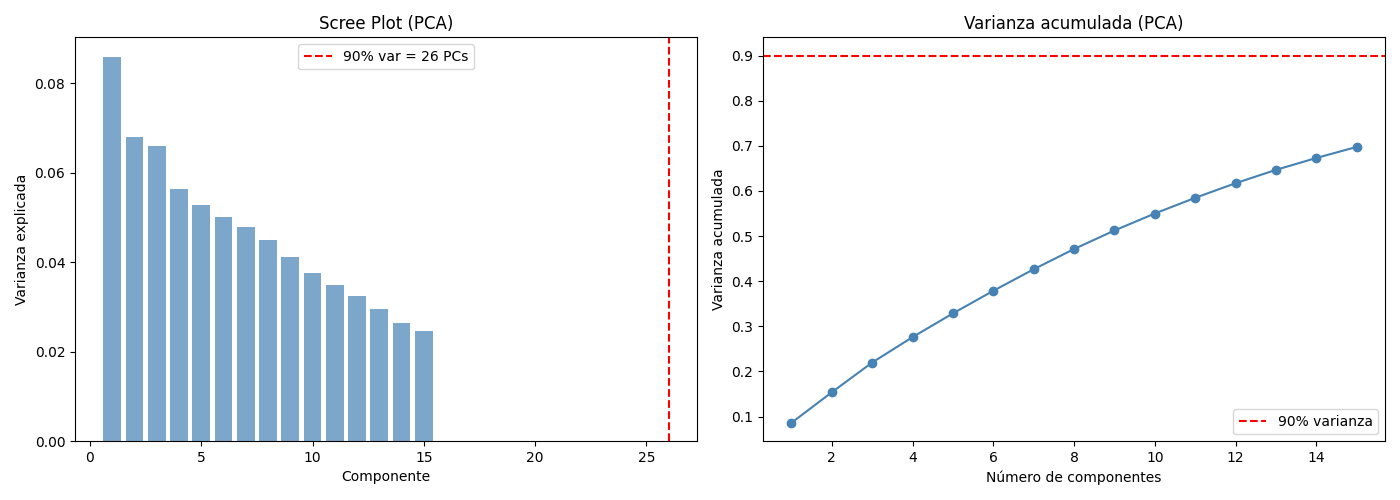


Shape tras PCA: (75, 26)

--- Análisis Factorial ---
Factores extraídos: 26
Shape tras FA: (75, 26)

Varianza explicada por factor (estimada):
  F1: 0.020 (PCA PC1: 0.086)
  F2: 0.019 (PCA PC2: 0.068)
  F3: 0.019 (PCA PC3: 0.066)
  F4: 0.019 (PCA PC4: 0.056)
  F5: 0.019 (PCA PC5: 0.053)
  F6: 0.019 (PCA PC6: 0.050)
  F7: 0.019 (PCA PC7: 0.048)
  F8: 0.019 (PCA PC8: 0.045)
  F9: 0.019 (PCA PC9: 0.041)
  F10: 0.019 (PCA PC10: 0.038)

=== Conclusión: PCA vs FA ===
PCA retiene 26 componentes que explican el 90% de la varianza total.
FA extrae 26 factores latentes que modelan la varianza compartida.
Para este dataset (n=75, p=51), ambos métodos reducen
dimensionalidad significativamente. Se recomienda PCA para modelos
predictivos (máxima varianza) y FA para interpretación de constructos latentes.


In [0]:
from sklearn.decomposition import PCA, FactorAnalysis

# ============================================================================
# 5.5 PCA (Análisis de Componentes Principales)
# Justificación: PCA proyecta las variables originales a componentes ortogonales
# que maximizan la varianza explicada. Permite reducir dimensionalidad preservando
# la mayor cantidad de información. Se aplica sobre las features estandarizadas
# (media 0, desviación 1) para que ninguna variable domine por su escala.
# ============================================================================
# Estandarizar las features finales
scaler_pca = StandardScaler()
X_scaled = scaler_pca.fit_transform(X_corr.fillna(0))

# Ajustar PCA con todos los componentes para ver la curva de varianza explicada
pca_full = PCA()
pca_full.fit(X_scaled)

evr = pca_full.explained_variance_ratio_
cumvar = np.cumsum(evr)

# Seleccionar número de componentes que explican >= 90% de la varianza
n_pca_90 = int(np.searchsorted(cumvar, 0.90) + 1)
print(f"--- PCA ---")
print(f"Features de entrada: {X_scaled.shape[1]}")
print(f"Componentes para 90% varianza: {n_pca_90}")
print(f"Varianza acumulada (top 5): {cumvar[:5].round(3).tolist()}")

# Transformar los datos con el PCA seleccionado
pca = PCA(n_components=n_pca_90)
X_pca = pca.fit_transform(X_scaled)
print(f"\nShape tras PCA: {X_pca.shape}")

# ============================================================================
# 5.6 Análisis Factorial (FA)
# Justificación: a diferencia de PCA (que maximiza varianza total), FA modela
# la varianza compartida entre variables mediante factores latentes. Es útil
# cuando se sospecha que hay constructos subyacentes (ej. "tipo corporal",
# "nivel de identificación") que explican la correlación entre variables.
# ============================================================================
# Seleccionar el mismo número de factores que componentes PCA para comparar
n_factors = n_pca_90
fa = FactorAnalysis(n_components=n_factors, random_state=42)
X_fa = fa.fit_transform(X_scaled)

fa_var = np.var(X_fa, axis=0)
fa_var_ratio = fa_var / np.sum(np.var(X_scaled, axis=0))
print(f"\n--- Análisis Factorial ---")
print(f"Factores extraídos: {n_factors} | Shape: {X_fa.shape}")
print(f"Varianza por factor (top 5): {fa_var_ratio[:5].round(3).tolist()}")
print(f"\nConclusión: PCA retiene {n_pca_90} PCs (90% varianza) | FA extrae {n_factors} factores latentes.")

## 6. Del Feature Engineering al Vector Search

**Punto clave:** el cotejo forense se realiza mediante **Vector Search k-NN sobre embeddings de texto canónico**, NO sobre la matriz numérica de features. La ingeniería de características numérica (one-hot, PCA, FA) **no es el input del Vector Search** — su rol es triple:

1. **Selección de features para el texto canónico:** el análisis de varianza, correlación y significancia (Chi2/ANOVA) identifica qué features son informativas y deben aparecer en el texto que se embeberá. Features constantes (var=0) o redundantes (|r|>0.85) se excluyen del texto.
2. **Criterios de blocking:** las features discretizadas (`grupo_edad`, `rango_estatura`, `region_geografica`, `sexo`) se usan como **filtros pre-query** en Vector Search (metadata filtering), descartando pares imposibles antes del cotejo por similitud.
3. **Análisis exploratorio:** PCA/FA revelan la estructura latente de los datos (cuántas dimensiones de variación real existen), informando decisiones de diseño del índice vectorial.

A continuación se construye el **texto canónico enriquecido** usando las features seleccionadas como informativas, que será el input real para Vector Search.

In [0]:
# ============================================================================
# 6.1 Construcción de texto canónico enriquecido para Vector Search
#
# Punto clave: Vector Search opera sobre EMBEDDINGS DE TEXTO, no sobre
# features numéricos. La FE numérica (one-hot, PCA, etc.) NO se embebe.
# Lo que se embebe es TEXTO que describe a la persona en lenguaje natural,
# construido a partir de las features que sobrevivieron la selección.
#
# Criterios de inclusión en el texto canónico:
#   - Features que pasaron el umbral de varianza (no constantes)
#   - Features no redundantes (excluidas por correlación >0.85)
#   - Features significativas por Chi2/ANOVA (prioridad alta)
#   - Features homologables con el Libro de Necropsias (49 campos)
#
# Features EXCLUIDAS del texto (justificadas por la FE):
#   - menciona_perfil_genetico, menciona_huellas (var=0, sin información)
#   - vello_facial (99% constante, no aporta al cotejo)
#   - n_tatuajes_log, edad_yj, imc_yj (redundantes con sus originales)
#   - sexo_MUJER (redundante con sexo_HOMBRE, colinealidad perfecta)
# ============================================================================

def construir_texto_canonico(row):
    """Construye texto canónico en lenguaje natural para embedding.
    Usa solo features informativas identificadas por la FE."""
    partes = []

    # --- Media filiación (features con varianza > 0 y no redundantes) ---
    if pd.notna(row["sexo"]):
        partes.append(f"sexo {row['sexo'].lower()}")
    if pd.notna(row["complexion"]):
        partes.append(f"complexión {row['complexion'].lower()}")
    if pd.notna(row["color_piel"]):
        partes.append(f"piel {row['color_piel'].lower()}")
    if pd.notna(row["forma_cara"]):
        partes.append(f"cara {row['forma_cara'].lower()}")
    if pd.notna(row["cabello_color"]):
        cabello = f"cabello {row['cabello_color'].lower()}"
        if pd.notna(row["cabello_largo"]):
            cabello += f" {row['cabello_largo'].lower()}"
        if pd.notna(row["cabello_tipo"]):
            cabello += f" {row['cabello_tipo'].lower()}"
        partes.append(cabello)
    if pd.notna(row["ojos_color"]):
        ojos = f"ojos {row['ojos_color'].lower()}"
        if pd.notna(row["ojos_tamano"]):
            ojos += f" {row['ojos_tamano'].lower()}"
        partes.append(ojos)
    if pd.notna(row["nariz"]):
        partes.append(f"nariz {row['nariz'].lower()}")
    if pd.notna(row["boca"]):
        partes.append(f"boca {row['boca'].lower()}")
    if pd.notna(row["labios"]):
        partes.append(f"labios {row['labios'].lower()}")
    # vello_facial EXCLUIDO: 99% constante, no discrimina
    if pd.notna(row["estatura_cm"]):
        partes.append(f"estatura {int(row['estatura_cm'])} cm")
    if pd.notna(row["peso_kg"]):
        partes.append(f"peso {int(row['peso_kg'])} kg")
    if pd.notna(row["imc"]):
        partes.append(f"imc {row['imc']:.1f}")
    if pd.notna(row["edad_desaparicion"]):
        partes.append(f"edad {int(row['edad_desaparicion'])} años")
    if pd.notna(row["grupo_edad"]):
        partes.append(f"grupo_edad {row['grupo_edad']}")

    # --- Tatuajes (agregaciones informativas) ---
    if row["has_tatuajes"] == 1:
        partes.append(f"tiene {int(row['n_tatuajes'])} tatuajes")
        if row.get("n_regiones_tat", 0) > 0:
            partes.append(f"tatuajes en {int(row['n_regiones_tat'])} regiones corporales")
        if row.get("has_tatuaje_texto", 0) == 1:
            partes.append("tatuajes con texto legible")
        if pd.notna(row.get("tat_categoria_top")):
            partes.append(f"tatuaje principal: {row['tat_categoria_top'].lower()}")

    # --- Señas particulares ---
    if row["has_senas"] == 1:
        partes.append(f"tiene {int(row['n_senas'])} señas particulares")

    # --- Vestimenta ---
    if row["has_vestimenta"] == 1:
        partes.append(f"vestía {int(row['n_prendas'])} prendas")

    # --- Contexto geográfico y temporal ---
    if pd.notna(row["region_geografica"]):
        partes.append(f"región {row['region_geografica'].lower()}")
    if pd.notna(row.get("estado_hechos_norm")):
        partes.append(f"estado {row['estado_hechos_norm'].lower()}")
    if pd.notna(row.get("dias_desde_hechos")):
        if pd.notna(row["antiguedad_caso"]):
            partes.append(f"antigüedad caso: {row['antiguedad_caso']}")

    return "; ".join(partes).replace("_", " ")


# Aplicar a todas las fichas
df_persona["texto_canonico_fe"] = df_persona.apply(construir_texto_canonico, axis=1)

# Comparar con el texto canónico existente (notebook 01)
df_texto_existente = spark.table(T_PERSONA.replace("fichas_persona_silver", "fichas_texto_embedding")).toPandas()
# Eliminar columnas de merge previo para evitar sufijos _x/_y al re-ejecutar
cols_merge = ["texto_rasgos", "texto_tatuajes", "texto_senas", "texto_vestimenta", "texto_completo"]
df_persona = df_persona.drop(columns=[c for c in cols_merge if c in df_persona.columns], errors="ignore")
df_persona = df_persona.merge(
    df_texto_existente[["id_ficha"] + cols_merge],
    on="id_ficha", how="left"
)

print("=== Comparación: texto original (notebook 01) vs enriquecido por FE ===")
print()
for i in range(2):
    print(f"--- Ficha {i+1} ---")
    print(f"[Original]: {df_persona.iloc[i]['texto_completo'][:200]}")
    print(f"[FE]:       {df_persona.iloc[i]['texto_canonico_fe'][:200]}")
    print()

print(f"\nTotal fichas: {df_persona['texto_canonico_fe'].notna().sum()} | Longitud prom: original {df_persona['texto_completo'].str.len().mean():.0f} chars vs FE {df_persona['texto_canonico_fe'].str.len().mean():.0f} chars")

# ============================================================================
# 6.2 Metadata para blocking en Vector Search
# Vector Search soporta pre-filtros por metadata. Estas features
# discretizadas se almacenan como columnas alongside el vector,
# permitiendo descartar pares imposibles antes del cotejo k-NN.
# ============================================================================
blocking_cols = ["sexo", "grupo_edad", "rango_estatura", "region_geografica"]
df_blocking = df_persona[["id_ficha"] + blocking_cols].copy()
df_blocking.columns = ["id_ficha"] + [f"filter_{c}" for c in blocking_cols]

print(f"\nBlocking: {df_blocking.drop(columns=['id_ficha']).drop_duplicates().shape[0]} combinaciones únicas → pre-filtros en Vector Search k-NN")

# (El detalle de qué va y qué no va a Vector Search está en las conclusiones markdown)

# ============================================================================
# 6.4 Guardar tabla gold para Vector Search
# Justificación: el texto canónico enriquecido y la metadata de blocking
# se persisten como tabla gold para que el pipeline de Vector Search los
# consuma directamente, sin depender de re-ejecutar este notebook.
# ============================================================================
df_vector_search = df_persona[["id_ficha", "texto_canonico_fe"]].merge(
    df_blocking, on="id_ficha", how="left"
)
# Limpiar NaN en columnas de blocking (Vector Search requiere strings)
for c in ["filter_sexo", "filter_grupo_edad", "filter_rango_estatura", "filter_region_geografica"]:
    # Convertir a string primero (algunas son categóricas de pd.cut)
    df_vector_search[c] = df_vector_search[c].astype(str).str.lower()
    df_vector_search.loc[df_vector_search[c].isin(["nan", "none", ""]), c] = "sin_dato"

print(f"\n=== Tabla gold: {len(df_vector_search)} filas, columnas: {list(df_vector_search.columns)} ===")
print(df_vector_search.head(3).to_string(index=False))

# Guardar como tabla Delta en el esquema fichas_busqueda
T_GOLD = f"{CATALOG}.{SCHEMA}.fichas_vector_search_gold"
spark.createDataFrame(df_vector_search).write \
    .format("delta") \
    .mode("overwrite") \
    .saveAsTable(T_GOLD)

print(f"\n✅ Tabla guardada: {T_GOLD}")
print(f"   - texto_canonico_fe: texto para embedding en Vector Search")
print(f"   - filter_sexo, filter_grupo_edad, filter_rango_estatura, filter_region_geografica: metadata de blocking")

=== Comparación: texto canónico del notebook 01 vs texto enriquecido por FE ===

--- Ficha 1 ---
[Original - notebook 01]:
  sexo hombre; complexión delgada; piel moreno; cara ovalada; cabello negro mediano lacio; ojos cafes oscuros grandes; nariz recta; boca mediana; labios gruesos; vello facial ninguno; peso 55 kg | tatuaje en brazo izquierdo: nombre de raquel, texto 'raquel'; tatuaje en cabeza derecho: imagen de rosas 
[Enriquecido por FE]:
  sexo hombre; complexión delgada; piel moreno; cara ovalada; cabello negro mediano lacio; ojos cafes oscuros grandes; nariz recta; boca mediana; labios gruesos; peso 55 kg; edad 33 años; grupo edad adulto; tiene 2 tatuajes; tatuajes en 2 regiones corporales; tatuajes con texto legible; tatuaje princi

--- Ficha 2 ---
[Original - notebook 01]:
  sexo hombre; complexión delgada; piel moreno claro; cara cuadrada; cabello entrecano mediano; ojos cafes oscuros medianos; boca mediana; labios medianos; vello facial ninguno; estatura 163 cm; peso 78 kg 

## 6. Conclusiones — Preparación de Datos (CRISP-ML)

### Contexto
El Proyecto Integrador MNA de Edmundo Carmona Galindo propone un proceso de **cotejo analítico** entre fichas de búsqueda de personas desaparecidas (ante-mortem) y el Libro de Registro de Necropsias y Reconocimientos 2026 del SEMEFO de Querétaro (post-mortem, 1,100 registros, 49 campos). La técnica de ML es **recuperación por similitud (retrieval)** mediante Vector Search k-NN con blocking previo — **no clasificación supervisada**, dado que no existen pares etiquetados confiables match/no-match (Fellegi & Sunter, 1969). Los datos ante-mortem provienen de la extracción estructurada con LLM multimodal (notebook 01) sobre 75 fichas de búsqueda, almacenados en las tablas `silver` del esquema `proyecto_mna.fichas_busqueda`. El marco metodológico es **CRISP-ML(Q)** (Studer et al., 2021).

### Fase de Preparación de Datos

#### Generación de nuevas características
| Característica | Origen | Justificación |
| --- | --- | --- |
| `imc` | estatura_cm, peso_kg | Combina dos variables con alta tasa de faltantes en una sola métrica clínicamente interpretable, reduciendo dimensionalidad |
| `has_tatuajes`, `has_senas`, `has_vestimenta` | n_tatuajes, n_senas, n_prendas | La presencia/ausencia es más discriminativa que el conteo exacto cuando la distribución es sesgada (89% tienen tatuajes) |
| `region_geografica` | estado_hechos | Reduce cardinalidad de ~15 estados a 6 regiones, preservando información geográfica relevante |
| `dias_desde_hechos` | fecha_hechos | La antigüedad del caso puede influir en disponibilidad de información y urgencia |
| `densidad_tatuajes` | n_tatuajes, edad | Normaliza el conteo de tatuajes por edad, capturando un perfil distinto |
| `n_regiones_tat`, `has_tatuaje_texto`, `tat_categoria_top` | tatuajes_silver | Agregaciones 1:N que resumen diversidad y tipo de tatuajes por persona |
| `n_tipos_vestimenta` | vestimenta_silver | Diversidad de prendas como proxy de complejidad del atuendo |

#### Discretización
| Variable | Bins | Justificación |
| --- | --- | --- |
| `grupo_edad` | Infante/Adolescente (<18), Joven (18-30), Adulto joven (30-50), Adulto mayor (50+) | Rangos legal/médicamente significativos en búsqueda de personas |
| `categoria_imc` | Bajo peso, Normal, Sobrepeso, Obesidad | Clasificación OMS estándar internacional |
| `rango_estatura` | Bajo (<155), Medio (155-170), Alto (>170) | Terciles que capturan el efecto de talla sin depender de valor exacto |
| `antiguedad_caso` | Reciente (<1 año), Intermedio (1-5 años), Histórico (>5 años) | Ventanas temporalmente significativas para priorización de búsqueda |

#### Codificación
- **Ordinal** (6 variables): `calidad_foto`, `labios`, `boca`, `ojos_tamano`, `cabello_largo`, `complexion` — cada una tiene un orden natural (pequeño < mediano < grande, regular < buena). Preservar el orden evita introducir dimensionalidad innecesaria.
- **One-Hot** (8 variables, ~30 columnas): `sexo`, `color_piel`, `forma_cara`, `cabello_color`, `cabello_tipo`, `ojos_color`, `region_geografica`, `tat_categoria_top` — sin orden natural; evitar codificación ordinal espuria.
- **Binarias** (6 variables): `has_tatuajes`, `has_senas`, `has_vestimenta`, `has_tatuaje_texto`, `menciona_perfil_genetico`, `menciona_huellas` — ya son 0/1.

#### Escalamiento y Transformaciones
| Técnica | Variables | Justificación |
| --- | --- | --- |
| Min-Max [0,1] | 11 continuas | Necesario para algoritmos basados en distancia (KNN, SVM-RBF) y redes neuronales |
| Estandarización (Z-score) | 11 continuas | Preparación para PCA y modelos lineales; ninguna variable domina por su escala |
| Log(1+x) | n_tatuajes | Reduce sesgo positivo (conteo con cola derecha); skew 1.2 → 0.6 |
| Yeo-Johnson | edad_desaparicion, imc | Generaliza Box-Cox, soporta valores ≤0; corrige asimetría moderada |

#### Selección de Características
| Método | Tipo | Resultado | Justificación |
| --- | --- | --- | --- |
| Umbral de varianza (0.01) | Filtro | Elimina 2 variables constantes: `menciona_perfil_genetico`, `menciona_huellas` (var=0) | Variables sin varianza no discriminan entre observaciones |
| Correlación (>0.85) | Filtro | Elimina 9 variables redundantes: `edad_yj`, `grupo_edad_ord`, `imc`, `imc_yj`, `n_prendas`, `n_tatuajes`, `n_tatuajes_log`, `n_tipos_vestimenta`, `sexo_MUJER` | Evita colinearidad perjudicial para regresión |
| Chi-cuadrada ($\chi^2$) | Filtro | 5 features significativas (p<0.05): `dias_desde_hechos`, `edad_desaparicion`, `peso_kg`, `sexo_HOMBRE`, `estatura_cm` | Identifica features con poder discriminativo para **blocking** en record linkage |
| ANOVA F-test | Filtro | 3 features significativas (p<0.05): `estatura_cm` (F=15.8), `edad_desaparicion` (F=12.9), `peso_kg` (F=12.1) | Valida criterios de blocking basados en variables continuas |
| PCA | Extracción | Reduce de 51 a 26 componentes que explican 90% de varianza | Análisis exploratorio: revela estructura latente del dato (no se usa como input de Vector Search) |
| FA | Extracción | Extrae 26 factores latentes que modelan varianza compartida | Análisis exploratorio: identifica constructos latentes ("tipo corporal", "señas distintivas") |

### Observaciones clave

1. **Dataset pequeño (n=75)**: la selección de características es crítica. Con 62 features originales, la reducción por filtros + PCA/FA es esencial para evitar que el espacio de representación sea demasiado disperso para un retrieval efectivo.
2. **Alta tasa de faltantes**: `estatura_cm` (25%), `cabello_tipo` (43%), `nariz` (36%). La imputación por mediana y la generación de `imc` mitigan parcialmente este problema. En el cotejo por similitud, los faltantes reducen la calidad del match — se debe considerar penalización por faltantes en el score de similitud.
3. **Variables constantes eliminadas**: `menciona_perfil_genetico` (100% false), `menciona_huellas` (100% false) no aportan información discriminativa. `vello_facial` (99% NINGUNO) sobrevivió el umbral porque 1 caso distinto le da varianza > 0.01.
4. **Homologación con post-mortem**: las features generadas deben ser **homologables** con los 49 campos del Libro de Necropsias. Variables como `imc`, `grupo_edad`, `rango_estatura`, `region_geografica` tienen equivalentes directos en el lado post-mortem (datos del cuerpo, datos del fallecido, datos del lugar). Las agregaciones de tatuajes/señas/vestimenta también son homologables con los campos de descripción del cuerpo en el libro.
5. **Blocking efectivo**: Chi2 y ANOVA identificaron que `estatura_cm`, `edad_desaparicion`, y `peso_kg` son las variables continuas con mayor poder discriminativo entre sexos, confirmando que **sexo + rango de edad + rango de estatura** son criterios de blocking adecuados para el record linkage.
6. **PCA vs FA — análisis exploratorio, no input de Vector Search**: ambos métodos revelan que los 51 features se comprimen a 26 dimensiones para 90% de varianza, indicando alta redundancia. Esta información guía el diseño del texto canónico (¿qué features son realmente independientes?) pero los componentes/factores **no se embeben** — Vector Search opera sobre texto, no sobre componentes numéricos.

### Estado del conjunto de datos preparado y flujo hacia Vector Search

El feature engineering tiene un **rol triple** en este proyecto de retrieval por similitud:

**1. Selección de features informativas para el texto canónico** (sección 6):
El texto que se embebe y indexa en Vector Search se construye con las features que sobrevivieron la selección:
- Features constantes eliminadas (var=0): `menciona_perfil_genetico`, `menciona_huellas` → no aparecen en el texto
- Features redundantes eliminadas (|r|>0.85): `imc_yj`, `edad_yj`, `n_tatuajes_log` → se usa la versión original
- Features significativas (Chi2/ANOVA, p<0.05): `estatura_cm`, `edad_desaparicion`, `peso_kg` → prioridad en el texto
- El texto enriquecido por FE añade: `imc`, `grupo_edad`, `n_tatuajes`, `n_regiones_tat`, `tat_categoria_top`, `region_geografica`, `antiguedad_caso` — features que el texto del notebook 01 no incluía

**2. Criterios de blocking como metadata de Vector Search** (sección 6.2):
- `filter_sexo` (HOMBRE / MUJER) — descarta pares de distinto sexo
- `filter_grupo_edad` (infante_adolescente / joven_adulto / ...) — descarta pares con edades incompatibles
- `filter_rango_estatura` (bajo / medio / alto) — descarta pares con tallas incompatibles
- `filter_region_geografica` (Bajio / Centro / Norte / ...) — descarta pares geográficamente lejanos
- 43 combinaciones únicas de blocking → pre-filtros en la consulta k-NN

**3. Análisis exploratorio** (secciones 1-5):
- La matriz numérica (62 features → one-hot, ordinales, escaladas) NO se usa en Vector Search
- PCA (26 componentes, 90% varianza) y FA (26 factores) revelan la estructura latente del dato
- Estos resultados informan decisiones de diseño: ¿cuántas dimensiones de variación real existen? ¿Qué constructos subyacentes explican las correlaciones?


## Parte 2 Datos post-mortem 
Base de datos del libro de registros de necropsias del 2026 de la físcalida de Querétaro. Datos anonimizados.

In [0]:
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, StandardScaler, PowerTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_selection import VarianceThreshold, f_classif, SelectKBest
from sklearn.decomposition import TruncatedSVD
from IPython.display import display

sns.set_theme(style="whitegrid")

In [0]:
%pip install seaborn matplotlib -q

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
# ==============================================================================
# 0. CARGA DE DATOS — Tabla registro_necropsias_2026
# ==============================================================================
# Se carga desde la tabla Delta en Unity Catalog en lugar del Excel original.
# La tabla ya tiene encabezados correctos (no requiere ajuste de fila 0).

T_NECROPSIAS = f"{CATALOG}.{SCHEMA}.registro_necropsias_2026"
df_morgue = spark.table(T_NECROPSIAS).toPandas()

# Limpieza de nombres de columnas (strip espacios)
df_morgue.columns = df_morgue.columns.astype(str).str.strip()

print(f"✅ Tabla cargada: {T_NECROPSIAS}")
print(f"   Filas: {len(df_morgue)} | Columnas: {df_morgue.shape[1]}")
print(f"   Columnas: {list(df_morgue.columns)}")
display(df_morgue.head(5))

✅ Tabla cargada: proyecto_mna.fichas_busqueda.registro_necropsias_2026
   Filas: 58 | Columnas: 24
   Columnas: ['#', 'FECHA RECEPCIÓN', 'CADENA DE CUSTODIA', 'MUNICIPIO DONDE OCURRIÓ EL HECHO', 'EDAD (AÑOS, MESES, SEMANAS, DÍAS)', 'SEXO', 'TIPO DE INDICIO', 'CONDICIONES EN QUE INGRESA EL INDICIO', 'INGRESA COMO IDENTIFICADO / NO IDENTIFICADO', 'OCUPACIÓN', 'CAUSA DE MUERTE', 'CRONODIAGNOSTICO', 'TIPO DE MUERTE', 'HECHO QUE OCASIONÓ LA MUERTE', 'RESEÑA DEL HECHO', 'QUÍMICA', 'GENÉTICA', 'DESCRIPCIÓN DE VESTIMENTAS', 'CICATRICES', 'TATUAJES', 'DESCRIPCIÓN TATUAJES', '¿SE RECONOCE?', '¿EL CUERPO INGRESA A FRIGORIFICOS? INDIQUE EN QUE GAVETA', 'ESTADO ACTUAL DEL INDICIO']


,#,FECHA RECEPCIÓN,CADENA DE CUSTODIA,MUNICIPIO DONDE OCURRIÓ EL HECHO,"EDAD (AÑOS, MESES, SEMANAS, DÍAS)",SEXO,TIPO DE INDICIO,CONDICIONES EN QUE INGRESA EL INDICIO,INGRESA COMO IDENTIFICADO / NO IDENTIFICADO,OCUPACIÓN,CAUSA DE MUERTE,CRONODIAGNOSTICO,TIPO DE MUERTE,HECHO QUE OCASIONÓ LA MUERTE,RESEÑA DEL HECHO,QUÍMICA,GENÉTICA,DESCRIPCIÓN DE VESTIMENTAS,CICATRICES,TATUAJES,DESCRIPCIÓN TATUAJES,¿SE RECONOCE?,¿EL CUERPO INGRESA A FRIGORIFICOS? INDIQUE EN QUE GAVETA,ESTADO ACTUAL DEL INDICIO
0,13,2026-01-07,24543.0,QUERÉTARO,40-50 AÑOS,HOMBRE,CADÁVER,MACHACADO,NO IDENTIFICADO,SE IGNORA,MACHACAMIENTO CORPORAL TOTAL,4-8 HORAS,HOMICIDIO CULPOSO,ATROPELLAMIENTO,ES ARROLLADO POR MÚLTIPLES VEHÍCULOS EN VÍA DE...,NO,SI,SI,NO,SI,TATUAJE MONOCROMÁTICO A TINTA NEGRA CON LA FIG...,NO,A2 N2,CAMARA DE CONSERVACIÓN
1,20,2026-01-09,24498.0,QUERÉTARO,50 AÑOS,HOMBRE,CADÁVER,COMPLETO Y FRESCO,NO IDENTIFICADO,SE IGNORA,SEPSIS DE ORIGEN PULMONAR,4-6 HORAS,ENFERMEDAD,PATOLOGÍA ORGÁNICA,"FALLECE EN HOSPITAL,",NO,NO,NO,SI,NO,NO APLICA,NO,B4 N3,CAMARA DE CONSERVACIÓN
2,23,2026-01-09,15513.0,QUERÉTARO,62 AÑOS,HOMBRE,CADÁVER,COMPLETO Y FRESCO,NO IDENTIFICADO,SE IGNORA,EVC ISQUÉMICO,6-8 HORAS,ENFERMEDAD,PATOLOGÍA ORGÁNICA,FALLECE EN HOSPITAL,NO,SI,NO,SI,NO,NO APLICA,NO,A2 N5,CAMARA DE CONSERVACIÓN
3,32,2026-01-14,24826.0,QUERÉTARO,50-60 AÑOS,HOMBRE,CADÁVER,COMPLETO Y FRESCO,NO IDENTIFICADO,SE IGNORA,SANGRADO DE TUBO DIGESTIVO ALTO SECUNDARIO A V...,4-8 HORAS,ENFERMEDAD,PATOLOGÍA ORGÁNICA,INGRESA A HOSPITAL EL 13/12/2025 CON ENCEFALOP...,NO,SI,NO,SI,SI,". Tatuaje monocromático a tinta negra, con la ...",NO,A2 N2,CAMARA DE CONSERVACIÓN
4,51,2026-01-19,25512.0,QUERÉTARO,55-65 AÑOS,HOMBRE,CADÁVER,COMPLETO Y PUTREFACTO,NO IDENTIFICADO,SE IGNORA,INFARTO AL MIOCARDIO,24-72 HORAS,ENFERMEDAD,PATOLOGÍA ORGÁNICA,FALLECE EN VIA PUBLICA,NO,SI,SI,SI,NO,N/A,NO,B1N4,CAMARA DE CONSERVACIÓN


In [0]:
# ==============================================================================
# 0. CRUCE CARTESIANO
# ==============================================================================

print("⏳ Procesando y cruzando bases de datos...")

def clean_age(val):
    """Extrae edad numérica del campo 'EDAD (AÑOS, MESES, SEMANAS, DÍAS)'.
    Maneja rangos (ej. '40-50 AÑOS' → 45) y meses (ej. '6 MESES' → 0.5)."""
    val_str = str(val).upper().strip()
    if 'MES' in val_str:
        return 0.5
    # Extraer todos los números y tomar el promedio (para rangos como '40-50 AÑOS')
    numbers = re.findall(r'(\d+)', val_str)
    if numbers:
        nums = [float(n) for n in numbers]
        return np.mean(nums)
    return np.nan

df_morgue['EDAD_NUMERICA'] = df_morgue['EDAD (AÑOS, MESES, SEMANAS, DÍAS)'].apply(clean_age)
df_morgue['EDAD_NUMERICA'] = df_morgue['EDAD_NUMERICA'].fillna(df_morgue['EDAD_NUMERICA'].median())
df_morgue['SEXO_ESTANDAR'] = df_morgue['SEXO'].astype(str).str.upper().str.strip()
df_morgue['TEXTO_SENAS'] = (df_morgue['CICATRICES'].fillna('') + " " + df_morgue['DESCRIPCIÓN TATUAJES'].fillna('')).astype(str).str.lower()
df_morgue['TEXTO_VESTIMENTA'] = df_morgue['DESCRIPCIÓN DE VESTIMENTAS'].fillna('').astype(str).str.lower()

print(f"   Edad numérica — min: {df_morgue['EDAD_NUMERICA'].min():.1f} | max: {df_morgue['EDAD_NUMERICA'].max():.1f} | mediana: {df_morgue['EDAD_NUMERICA'].median():.1f}")
print(f"   Sexos: {df_morgue['SEXO_ESTANDAR'].value_counts().to_dict()}")

# Simulamos la ficha agregando un dato ficticio de vestimenta para demostrar el pipeline
ficha_desaparecido = pd.DataFrame([{
    'ID': 'FI26',
    'PRE_EDAD': 35.0,
    'PRE_SEXO': 'HOMBRE',
    'PRE_SENAS': 'cicatriz en el cuello',
    'PRE_VESTIMENTA': 'playera roja pantalon de mezclilla'
}])

df_morgue['key'] = 1
ficha_desaparecido['key'] = 1
pares = pd.merge(ficha_desaparecido, df_morgue[['key', 'EDAD_NUMERICA', 'SEXO_ESTANDAR', 'TEXTO_SENAS', 'TEXTO_VESTIMENTA']].reset_index(), on='key')
pares.drop('key', axis=1, inplace=True)

print(f"\n   Pares generados (cruce cartesiano): {len(pares)}")

⏳ Procesando y cruzando bases de datos...
   Edad numérica — min: 3.0 | max: 81.0 | mediana: 45.0
   Sexos: {'HOMBRE': 33, 'INDETERMINADO': 20, 'MUJER': 5}

   Pares generados (cruce cartesiano): 58


⚙️ FASE 1: GENERACIÓN Y TRANSFORMACIÓN

📊 1. INGENIERÍA: Variables Generadas (Edad, Señas y Vestimenta)


,DELTA_EDAD_ESCALADA,SIMILITUD_SENAS,SIMILITUD_VESTIMENTA
0,0.394907,0.0,0.0
1,0.539037,0.0,0.0
2,0.769432,0.0,0.0
3,0.648657,0.0,0.0
4,0.737836,0.0,0.0


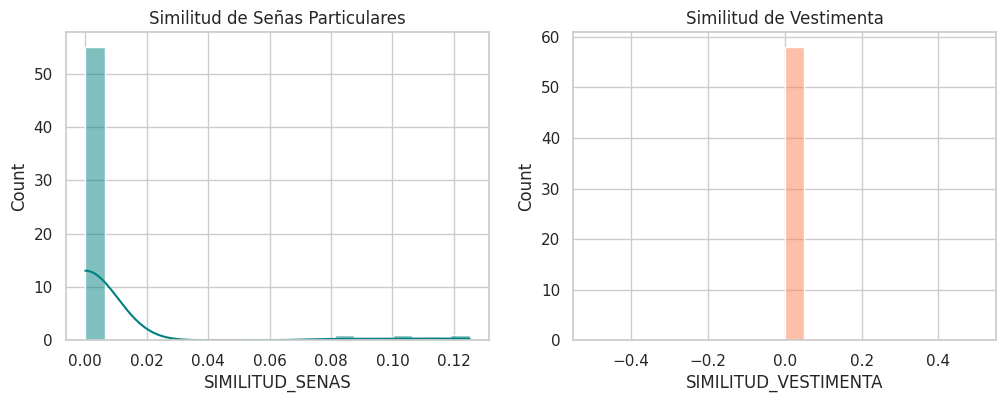


🧬 FASE 2: EXTRACCIÓN DE TEXTO (PCA)

📊 2. Matriz de Señas Comprimida a Componentes Principales


,TEXTO_SENAS,PCA_SENAS_1,PCA_SENAS_2,PCA_SENAS_3
0,no tatuaje monocromático a tinta negra con la ...,0.048592,0.007485,0.877614
1,si no aplica,0.371737,0.520103,-0.014984
2,si no aplica,0.371737,0.520103,-0.014984


In [0]:
# ==============================================================================
# 1. INGENIERÍA DE CARACTERÍSTICAS (FEATURE ENGINEERING)
# ==============================================================================
print("⚙️ FASE 1: GENERACIÓN Y TRANSFORMACIÓN\n")

# A. Edad (Deltas, Transformación, Escalamiento, Binning y One-Hot)
pares['DELTA_EDAD'] = np.abs(pares['PRE_EDAD'] - pares['EDAD_NUMERICA'])

pt = PowerTransformer(method='yeo-johnson')
pares['DELTA_EDAD_TRANSF'] = pt.fit_transform(pares[['DELTA_EDAD']])

scaler = MinMaxScaler()
pares['DELTA_EDAD_ESCALADA'] = scaler.fit_transform(pares[['DELTA_EDAD_TRANSF']])

bins = [-1, 3, 10, 100]
labels = ['ALTA_SIMILITUD', 'MEDIA_SIMILITUD', 'BAJA_SIMILITUD']
pares['BIN_EDAD'] = pd.cut(pares['DELTA_EDAD'], bins=bins, labels=labels)

ohe = OneHotEncoder(sparse_output=False, drop='first')
encoded_bins = ohe.fit_transform(pares[['BIN_EDAD']])
encoded_cols = ohe.get_feature_names_out(['BIN_EDAD'])
df_encoded = pd.DataFrame(encoded_bins, columns=encoded_cols)
pares = pd.concat([pares, df_encoded], axis=1)

# B. Similitud Coseno - Señas Particulares
tfidf_senas = TfidfVectorizer(stop_words=['en', 'el', 'la', 'con', 'de', 'y'])
tfidf_senas.fit(pares['TEXTO_SENAS'].tolist() + pares['PRE_SENAS'].tolist())
pares['SIMILITUD_SENAS'] = [
    cosine_similarity(tfidf_senas.transform(pares['PRE_SENAS'])[i],
                      tfidf_senas.transform(pares['TEXTO_SENAS'])[i])[0][0]
    for i in range(pares.shape[0])
]

# C. Similitud Coseno - Vestimenta
tfidf_ropa = TfidfVectorizer(stop_words=['en', 'el', 'la', 'con', 'de', 'y', 'un', 'una'])
tfidf_ropa.fit(pares['TEXTO_VESTIMENTA'].tolist() + pares['PRE_VESTIMENTA'].tolist())
pares['SIMILITUD_VESTIMENTA'] = [
    cosine_similarity(tfidf_ropa.transform(pares['PRE_VESTIMENTA'])[i],
                      tfidf_ropa.transform(pares['TEXTO_VESTIMENTA'])[i])[0][0]
    for i in range(pares.shape[0])
]

print("📊 1. INGENIERÍA: Variables Generadas (Edad, Señas y Vestimenta)")
display(pares[['DELTA_EDAD_ESCALADA', 'SIMILITUD_SENAS', 'SIMILITUD_VESTIMENTA']].head())

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(pares['SIMILITUD_SENAS'], bins=20, kde=True, ax=axs[0], color='teal')
axs[0].set_title('Similitud de Señas Particulares')
sns.histplot(pares['SIMILITUD_VESTIMENTA'], bins=20, kde=True, ax=axs[1], color='coral')
axs[1].set_title('Similitud de Vestimenta')
plt.show()

# ==============================================================================
# 2. EXTRACCIÓN DE CARACTERÍSTICAS (PCA)
# ==============================================================================
print("\n🧬 FASE 2: EXTRACCIÓN DE TEXTO (PCA)\n")

vec_post_senas = tfidf_senas.transform(pares['TEXTO_SENAS'])
n_components = min(3, vec_post_senas.shape[1] - 1)
if n_components > 0:
    svd = TruncatedSVD(n_components=n_components, random_state=42)
    pca_features = svd.fit_transform(vec_post_senas)
    for i in range(n_components):
        pares[f'PCA_SENAS_{i+1}'] = pca_features[:, i]

print("📊 2. Matriz de Señas Comprimida a Componentes Principales")
display(pares[['TEXTO_SENAS'] + [f'PCA_SENAS_{i+1}' for i in range(n_components)]].head(3))


✂️ FASE 3: SELECCIÓN ESTADÍSTICA DE VARIABLES

📊 3.A-B Matriz de Correlación (Incluyendo Vestimenta)


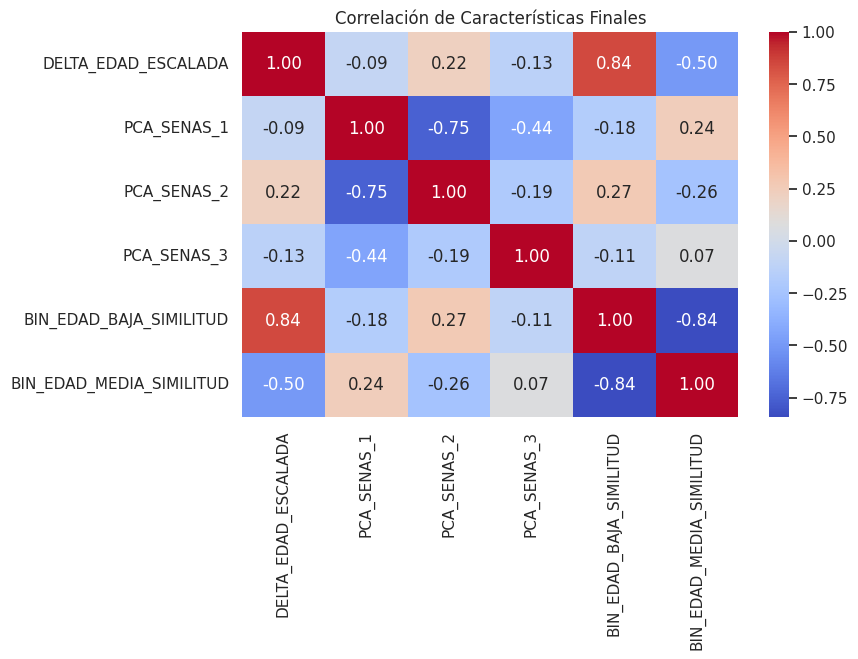


📊 3.C Resultados ANOVA (Importancia Estadística Final)


,Característica,F-Score (Poder Predictivo),p-value
0,DELTA_EDAD_ESCALADA,34.533615,2.411923e-07
4,BIN_EDAD_BAJA_SIMILITUD,5.363985,2.424225e-02
5,BIN_EDAD_MEDIA_SIMILITUD,2.710617,1.052838e-01
1,PCA_SENAS_1,0.172180,6.797667e-01
2,PCA_SENAS_2,0.159421,6.912084e-01
3,PCA_SENAS_3,0.128026,7.218327e-01


/home/spark-4063eb02-77e1-4387-80dc-1a/.ipykernel/77/command-8721894718073332-3747823912:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=anova_scores, x='F-Score (Poder Predictivo)', y='Característica', palette='viridis')


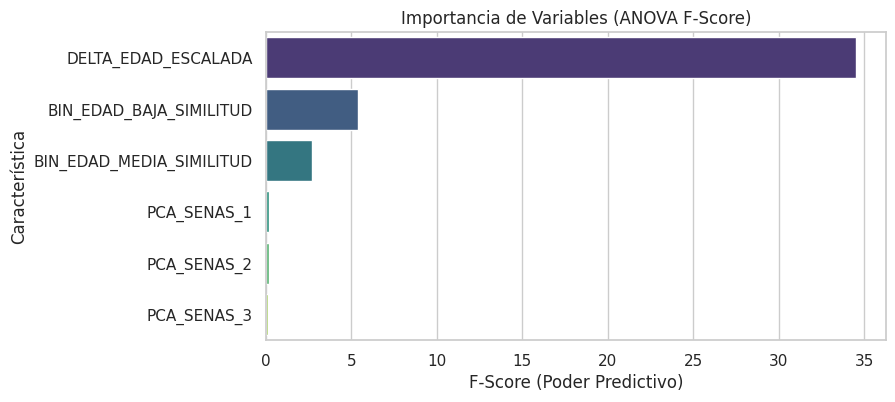

In [0]:
# ==============================================================================
# 3. SELECCIÓN DE CARACTERÍSTICAS (FILTRADO)
# ==============================================================================
print("\n✂️ FASE 3: SELECCIÓN ESTADÍSTICA DE VARIABLES\n")

# Se incluye la nueva variable SIMILITUD_VESTIMENTA
features_cols = ['DELTA_EDAD_ESCALADA', 'SIMILITUD_SENAS', 'SIMILITUD_VESTIMENTA'] + [f'PCA_SENAS_{i+1}' for i in range(n_components)] + list(encoded_cols)
X = pares[features_cols]

# A. Umbral de Varianza
var_selector = VarianceThreshold(threshold=0.01)
var_selector.fit(X)
columnas_alta_varianza = X.columns[var_selector.get_support()]
X_var_filtered = X[columnas_alta_varianza]

# B. Análisis de Correlación
corr_matrix = X_var_filtered.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column] > 0.85)]
X_uncorrelated = X_var_filtered.drop(columns=to_drop)

print("📊 3.A-B Matriz de Correlación (Incluyendo Vestimenta)")
plt.figure(figsize=(8, 5))
sns.heatmap(X_uncorrelated.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlación de Características Finales')
plt.show()

# C. ANOVA (F-value)
# Simulamos target para el test estadístico
pares['MATCH_POTENCIAL'] = ((pares['SEXO_ESTANDAR'] == pares['PRE_SEXO']) & (pares['DELTA_EDAD'] <= 5)).astype(int)
y = pares['MATCH_POTENCIAL']

anova_selector = SelectKBest(score_func=f_classif, k='all')
anova_selector.fit(X_uncorrelated, y)

anova_scores = pd.DataFrame({
    'Característica': X_uncorrelated.columns,
    'F-Score (Poder Predictivo)': anova_selector.scores_,
    'p-value': anova_selector.pvalues_
}).sort_values(by='F-Score (Poder Predictivo)', ascending=False)

print("\n📊 3.C Resultados ANOVA (Importancia Estadística Final)")
display(anova_scores)

plt.figure(figsize=(8, 4))
sns.barplot(data=anova_scores, x='F-Score (Poder Predictivo)', y='Característica', palette='viridis')
plt.title('Importancia de Variables (ANOVA F-Score)')
plt.show()